# Qwen3-0.6B · LoRA riêng cho ngữ pháp và cách nói tự nhiên

Nguồn nghiên cứu: [BEA-2019 / W&I+LOCNESS](https://aclanthology.org/W19-4406/),
[trang phát hành Cambridge](https://www.cl.cam.ac.uk/research/nl/bea2019st/) và
[JFLEG / EACL-2017](https://aclanthology.org/E17-2037/),
[repository tác giả](https://github.com/keisks/jfleg).

Nhãn sửa câu do người tạo trong các corpus; không dùng Qwen tự sinh nhãn đúng cho chính nó.
Dữ liệu văn viết, chưa chứng minh chất lượng trên hội thoại nói tự do hoặc transcript ASR lỗi.
**Chỉ sử dụng phi thương mại theo giấy phép gốc. Không phát tán corpus/LOCNESS qua Git hoặc link public.**

Run All mặc định chỉ đọc dữ liệu và vẽ biểu đồ. Các cell train/inference đều tắt; bạn tự chủ động chạy.

In [1]:
import json, sys, subprocess
from pathlib import Path
from collections import Counter
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'scripts/grammar_data.py').exists())
sys.path.insert(0, str(ROOT)) if str(ROOT) not in sys.path else None
from scripts.grammar_data import load, object_sha
DATA = ROOT/'data/processed/grammar-wi-jfleg-v1'
CONFIG = ROOT/'configs/grammar_qwen3_06b_qlora.json'
PYTHON = ROOT/('.venv/Scripts/python.exe' if sys.platform == 'win32' else '.venv/bin/python')
if not PYTHON.exists(): PYTHON = Path(sys.executable)
parts, manifest = load(DATA)
config = json.loads(CONFIG.read_text(encoding='utf-8'))
print('Manifest SHA256:', object_sha(manifest))
print('Weights/model inference were not loaded. Training has not been requested by this notebook.')

Manifest SHA256: 84d7a4249a509de4b92b563f9efbb83c65e7952989ae415b7fbd0bf8f4b42d56
Weights/model inference were not loaded. Training has not been requested by this notebook.


## 1. Nguồn và quy tắc chia tập

W&I train gốc: 34.308 câu; W&I+LOCNESS dev: 4.384 câu. LOCNESS không có tập train được phát hành.
Dành 10% nhóm người viết trong W&I train làm **internal grammar test**, không phải BEA official test.
W&I dev giữ để validation; loại các bài train có người viết xuất hiện trong dev.

JFLEG dev 754 câu được chia theo câu 80/20 cho train/validation; bốn bản sửa của một câu luôn cùng tập.
JFLEG test 747 câu giữ nguyên để đánh giá sau khi khóa recipe. **Không báo điểm JFLEG dev như benchmark độc lập**.
JFLEG không có ID người viết nên không tuyên bố chia theo người viết cho nguồn này.
Test W&I chính thức chỉ có input, không có gold trong archive; chỉ giữ input để tránh contamination.
Loại câu có nhãn UNK/Um, câu rỗng và các trùng source/reference theo chuẩn hóa chữ, dấu và khoảng trắng.

In [2]:
table = pd.DataFrame(manifest['stats']).T
display(table[['rows','source_sentences','groups','unchanged_rows','max_tokens','p95_tokens']])
display(pd.DataFrame(manifest['leakage']).T)
display(pd.Series(manifest['official_source_counts'], name='Official source sentences').to_frame())
display(pd.Series(manifest['excluded_source_groups'], name='Excluded source groups').to_frame())
assert all(v == 0 for pair in manifest['leakage'].values() for v in pair.values())

,rows,source_sentences,groups,unchanged_rows,max_tokens,p95_tokens
train,28501,27126,2667,8773,607,230
validation,4292,4292,503,1470,478,236
test,3746,3746,990,1058,442,231


,text_overlap,group_overlap
train/validation,0,0
train/test,0,0
validation/test,0,0


,Official source sentences
wi_locness:train,34308
wi_locness:dev,4384
jfleg:dev,754
jfleg:test,747


,Excluded source groups
test:unknown_reference,160
test:cross_split_overlap,93
test:duplicate_source,20
validation:unknown_reference,155
validation:cross_split_overlap,84
validation:duplicate_source,12
train:unknown_reference,1232
train:cross_split_overlap,898
train:duplicate_source,185
train:empty,8


## 2. Phân bố dữ liệu

Một câu JFLEG train có thể tạo nhiều mẫu từ các bản sửa khác nhau của người; chỉ giữ các target khác nhau.
Validation/test mỗi câu có một record và giữ toàn bộ reference để chấm. Không nhân số lượng test bằng số reference.
Unchanged nghĩa là source bằng target sau cùng một bước ghép token, không phải lời khẳng định mọi người đều thấy câu hoàn hảo.

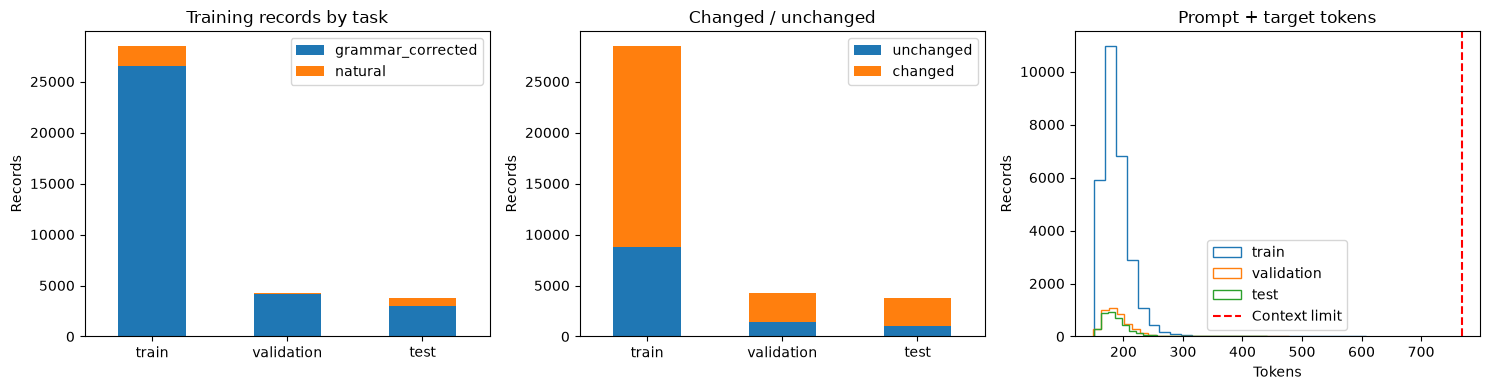

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
pd.DataFrame({s: manifest['stats'][s]['tasks'] for s in parts}).T.plot.bar(stacked=True, ax=axes[0], rot=0)
axes[0].set(title='Training records by task', ylabel='Records')
pd.DataFrame({s: {'unchanged': manifest['stats'][s]['unchanged_rows'],
                     'changed': len(parts[s])-manifest['stats'][s]['unchanged_rows']} for s in parts}).T.plot.bar(stacked=True, ax=axes[1], rot=0)
axes[1].set(title='Changed / unchanged', ylabel='Records')
for split, rows in parts.items():
    axes[2].hist([r['total_tokens'] for r in rows], bins=25, histtype='step', label=split)
axes[2].axvline(config['max_length'], color='red', linestyle='--', label='Context limit')
axes[2].set(title='Prompt + target tokens', xlabel='Tokens', ylabel='Records')
axes[2].legend()
plt.tight_layout()
plt.show()

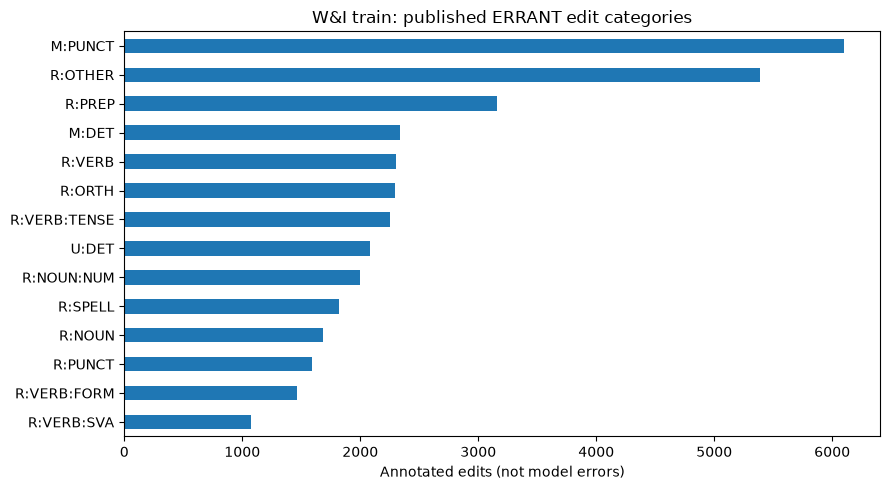

In [4]:
errors = Counter(e['type'] for row in parts['train'] if row['corpus']=='wi_locness' for e in row['edits'] if e['type']!='noop')
pd.Series(errors).sort_values().tail(14).plot.barh(figsize=(9, 5), title='W&I train: published ERRANT edit categories')
plt.xlabel('Annotated edits (not model errors)')
plt.tight_layout()
plt.show()

## 3. Nhãn thực sự được học

Cùng một adapter học hai yêu cầu: `grammar_corrected` dùng W&I và `natural` dùng JFLEG.
Mỗi record chỉ có **một target JSON key** đã được nguồn đó gán nhãn; không tự bịa target natural cho W&I,
không dùng bản fluency làm nhãn minimal-grammar, không bịa explanation của chuyên gia.
Phần prompt bị mask -100; chỉ token target JSON và EOS tham gia loss. Không cắt mất nhãn dài.
Target W&I còn gồm chính tả/từ vựng; không phải corpus chỉ có ngữ pháp.

Đây là contract train/eval riêng. Web hiện vẫn dùng base Qwen với contract ba trường; sau benchmark cần nối adapter bằng
hai request đúng task (hoặc đánh giá cách hợp nhất khác). Notebook không tự thay model đang phục vụ.

In [5]:
# Chỉ một đoạn W&I ngắn trong notebook để hạn chế trích lại corpus.
grammar = next(r for r in parts['train'] if r['corpus']=='wi_locness' and len(r['source'].split()) < 16
               and any(e['type']=='R:VERB:SVA' for e in r['edits']))
natural = next(r for r in parts['train'] if r['corpus']=='jfleg' and r['source']!=r['target'] and len(r['source'].split())<18)
display(pd.DataFrame([{k:r[k] for k in ['task','source','target','label_origin']} for r in [grammar, natural]]))
print('Max tokens:', max(r['total_tokens'] for rows in parts.values() for r in rows))
print('Train unchanged:', manifest['stats']['train']['unchanged_rows'])

,task,source,target,label_origin
0,grammar_corrected,The movie is about Lucy's family that moves in...,"The movie is about Lucy's family, who move int...",published_human_correction
1,natural,For not use car.,Not for use with a car.,published_human_correction


Max tokens: 607
Train unchanged: 8773


## 4. Tái tạo và kiểm tra trước khi train

Máy hiện tại đã có dữ liệu. Trên máy mới, tải base Qwen bằng downloader của project, cài requirements/feedback.txt,
requirements/feedback-evaluation.txt và nltk; giữ bản PyTorch CUDA phù hợp máy.
`prepare --download` kiểm SHA256 của archive Cambridge và file JFLEG tại commit cố định.
Nếu dataset output đã tồn tại, dùng `check`; không ghi đè tập đã đóng băng.

In [6]:
def command(*arguments):
    cmd = [str(PYTHON), '-X', 'utf8', *map(str, arguments)]
    print(subprocess.list2cmdline(cmd))
    return cmd
prepare_cmd = command('scripts/grammar_data.py','prepare','--download')
check_cmd = command('scripts/train_grammar_model.py','--check-data-only')
RUN_CHECK = False
if RUN_CHECK: subprocess.run(check_cmd,cwd=ROOT,check=True)

D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 scripts/grammar_data.py prepare --download
D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 scripts/train_grammar_model.py --check-data-only


## 5. Đánh giá bản gốc trước train

Dùng đúng prompt, tập và cấu hình sinh của evaluator cho cả trước/sau; giữ raw output và lỗi JSON.
Lệnh dưới dùng validation để phát triển. Có thể thêm `--limit 50` cho cả hai lượt để kiểm tra kỹ thuật,
nhưng không dùng lượt ít mẫu đó làm kết luận benchmark. Chỉ chạy full test sau khi đã khóa recipe.
Cell này không chạy model khi Run All.

In [7]:
before_cmd = command('scripts/evaluate_grammar_model.py','--split','validation',
                     '--output','data/generated/grammar-benchmark-v1/before-validation','--run')
RUN_BASELINE = False
if RUN_BASELINE: subprocess.run(before_cmd,cwd=ROOT,check=True)

D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 scripts/evaluate_grammar_model.py --split validation --output data/generated/grammar-benchmark-v1/before-validation --run


## 6. Bạn chủ động bắt đầu train

QLoRA NF4 rank 8 trên q_proj/v_proj; base Qwen đóng băng, chỉ adapter Qwen được cập nhật.
Wav2vec2 và projector không được nạp hay cập nhật. Recipe mặc định 2 epochs, batch 1 × accumulation 16,
context 768, gradient checkpointing, loss projection theo chunk. Chọn checkpoint bằng validation loss.
Cấu hình nhằm giảm bộ nhớ; chưa xác nhận vừa GPU 4 GB bằng lượt train thật. Thời gian/VRAM cần đo trên máy chạy.
Output riêng, không ghi đè adapter phát âm. Log nằm trong training_history.jsonl và trainer_state.json/checkpoint.

In [8]:
train_cmd = command('scripts/train_grammar_model.py','--run')
resume_cmd = command('scripts/train_grammar_model.py','--run','--resume')
print('Adapter output:', config['output_dir']+'/adapter')
RUN_TRAIN = False
if RUN_TRAIN:
    subprocess.run(check_cmd,cwd=ROOT,check=True)
    subprocess.run(train_cmd,cwd=ROOT,check=True)

D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 scripts/train_grammar_model.py --run
D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 scripts/train_grammar_model.py --run --resume
Adapter output: runs/grammar-qwen3-06b-wi-jfleg-v1/adapter


## 7. Đánh giá sau train và so sánh

Evaluator yêu cầu adapter đã completed và khớp dataset/base weights. Trước/sau phải khớp prompt,
ordered IDs, precision, device, seed và generation settings; không dùng fallback để biến lỗi thành thành công.
Chỉ số: tỷ lệ JSON hợp lệ, exact match với bất kỳ reference, chrF và giữ nguyên câu có reference không sửa.
Đây là diagnostics văn bản, **không gọi là accuracy ngữ pháp**, không thay thế ERRANT F0.5, JFLEG GLEU,
kiểm tra giữ nguyên ý hoặc chấm fluency của người. Chưa có điểm sau train khi adapter chưa tồn tại.

In [9]:
after_cmd = command('scripts/evaluate_grammar_model.py','--split','validation',
                    '--adapter',config['output_dir']+'/adapter',
                    '--output','data/generated/grammar-benchmark-v1/after-validation','--run')
compare_cmd = command('scripts/evaluate_grammar_model.py','--compare',
                      'data/generated/grammar-benchmark-v1/before-validation',
                      'data/generated/grammar-benchmark-v1/after-validation',
                      '--output','data/generated/grammar-benchmark-v1/comparison-validation.json')
RUN_AFTER = False
if RUN_AFTER:
    subprocess.run(after_cmd,cwd=ROOT,check=True)
    subprocess.run(compare_cmd,cwd=ROOT,check=True)

D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 scripts/evaluate_grammar_model.py --split validation --adapter runs/grammar-qwen3-06b-wi-jfleg-v1/adapter --output data/generated/grammar-benchmark-v1/after-validation --run
D:\NCC\MDD\.venv\Scripts\python.exe -X utf8 scripts/evaluate_grammar_model.py --compare data/generated/grammar-benchmark-v1/before-validation data/generated/grammar-benchmark-v1/after-validation --output data/generated/grammar-benchmark-v1/comparison-validation.json


In [10]:
report_path = ROOT/'data/generated/grammar-benchmark-v1/comparison-validation.json'
if report_path.exists():
    report = json.loads(report_path.read_text(encoding='utf-8'))
    metrics = pd.DataFrame({(stage,task): values for stage in ['before','after']
                           for task,values in report[stage]['tasks'].items()}).T
    display(metrics)
    numeric = metrics[['valid_json_rate','exact_reference_match','unchanged_preservation_rate']].astype(float)
    numeric.plot.bar(figsize=(11,4), ylim=(0,1), title='Before/after · text diagnostics')
    plt.tight_layout(); plt.show()
else:
    print('Chưa có kết quả trước/sau model. Dataset đã sẵn sàng; không bịa điểm sau train.')
history = ROOT/config['output_dir']/'training_history.jsonl'
if history.exists():
    logs = pd.DataFrame(json.loads(line) for line in history.read_text(encoding='utf-8').splitlines())
    for col in ['loss','eval_loss']:
        if col in logs: plt.plot(logs['step'],logs[col],marker='.',label=col)
    plt.xlabel('Optimizer step'); plt.ylabel('Loss'); plt.legend(); plt.show()
else:
    print('Chưa có log train của LoRA ngữ pháp riêng.')

Chưa có kết quả trước/sau model. Dataset đã sẵn sàng; không bịa điểm sau train.
Chưa có log train của LoRA ngữ pháp riêng.
